# DAY5 과제 02 : 종합실습 — 제철소 전력 사용

데이터 파일 : `Steel_industry_data.csv` (DAY1 · DAY3 실습과 같은 파일)
출처 : UCI Machine Learning Repository - [Steel Industry Energy Consumption](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption)

 15분마다 한 번씩 기록되어 총 35,040행이고, 한 행이 15분 한 구간이다.
**기술통계 → 두 집단 비교 → 여러 집단 비교 → 범주형 검정 → 상관분석**을 한 데이터로 차례대로 해 본다.


- 유의수준은 α = 0.05, 양측으로 한다
- 결론은 두 줄로 쓴다 — 통계적 결론과 사실적 결론
- 이 자료는 같은 공장을 시간 순서로 이어 기록한 것이라 관측끼리 엄밀히는 독립이 아니다. 검정 결과는 독립을 가정한 계산으로 해석한다

| 원래 열 이름 | 바꿀 이름 | 뜻 |
|---|---|---|
| date | 날짜 | 기록 시각 (15분 단위, 일/월/년 순서) |
| Usage_kWh | 전력사용량 | 15분 구간의 사용 전력량 (kWh) |
| Lagging_Current_Reactive.Power_kVarh | 지상무효전력 | 모터 등 유도성 설비가 만드는 무효전력량 (kVarh) |
| Leading_Current_Reactive_Power_kVarh | 진상무효전력 | 콘덴서 등 용량성 설비가 만드는 무효전력량 (kVarh) |
| CO2(tCO2) | 탄소배출량 | 탄소 배출량 (tCO2) |
| Lagging_Current_Power_Factor | 지상역률 | 지상 역률 (%) |
| Leading_Current_Power_Factor | 진상역률 | 진상 역률 (%) |
| NSM | 초단위시각 | 자정부터 지난 초 |
| WeekStatus | 주중주말 | Weekday(주중) · Weekend(주말) |
| Day_of_week | 요일 | Monday ~ Sunday |
| Load_Type | 부하유형 | Light_Load(경부하) · Medium_Load(중부하) · Maximum_Load(최대부하) |

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "Steel_industry_data.csv")

df = pd.read_csv(csv_path)

data = df.copy()

## 1부. 기술통계

### 1. 위 표대로 열 이름을 바꾸고, `날짜` 를 날짜형으로 바꾼 뒤 시각을 뗀 `일자` 열을 만드시오. 행 · 열 수, 결측치 합계, 기록 기간(첫 시각 ~ 마지막 시각)을 확인하시오.

In [ ]:
data = data.rename(columns={
    "date": "날짜",
    "Usage_kWh": "전력사용량",
    "Lagging_Current_Reactive.Power_kVarh": "지상무효전력",
    "Leading_Current_Reactive_Power_kVarh": "진상무효전력",
    "CO2(tCO2)": "탄소배출량",
    "Lagging_Current_Power_Factor": "지상역률",
    "Leading_Current_Power_Factor": "진상역률",
    "NSM": "초단위시각",
    "WeekStatus": "주중주말",
    "Day_of_week": "요일",
    "Load_Type": "부하유형",
})
data["날짜"] = pd.to_datetime(data["날짜"], format="%d/%m/%Y %H:%M")     # 일/월/년 순서라 format 을 알려 준다
data["일자"] = data["날짜"].dt.date                                       # 시각을 뗀 날짜 (하루 단위로 묶을 때 쓴다)

print("행·열:", data.shape)
print("결측치 합계:", data.isna().sum().sum())
print("기간:", data["날짜"].min(), "~", data["날짜"].max())

행·열: (35040, 12)
결측치 합계: 0
기간: 2018-01-01 00:00:00 ~ 2018-12-31 23:45:00


### 2. `부하유형` 의 건수와 비율(%)을 한 표로 구하시오. (비율은 소수 첫째 자리까지)

In [ ]:
load_table = pd.DataFrame({"건수": data["부하유형"].value_counts(),
                           "비율(%)": (data["부하유형"].value_counts(normalize=True) * 100).round(1)})
load_table

,건수,비율(%)
부하유형,,
Light_Load,18072,51.6
Medium_Load,9696,27.7
Maximum_Load,7272,20.8


### 3. 15분 `전력사용량` 의 평균 · 중앙값 · 표준편차 · 최솟값 · 1사분위수 · 3사분위수 · 최댓값 · IQR · 왜도를 구하시오. (소수 둘째 자리까지)

In [ ]:
usage = data["전력사용량"]
display(usage.describe().round(2))
print("중앙값:", round(usage.median(), 2))
print("IQR:", round(usage.quantile(0.75) - usage.quantile(0.25), 2))
print("왜도:", round(usage.skew(), 2))

count    35040.00
mean        27.39
std         33.44
min          0.00
25%          3.20
50%          4.57
75%         51.24
max        157.18
Name: 전력사용량, dtype: float64

중앙값: 4.57
IQR: 48.04
왜도: 1.2


### 4. 15분 `전력사용량` 의 히스토그램과 상자그림을 1행 2열로 그리시오.

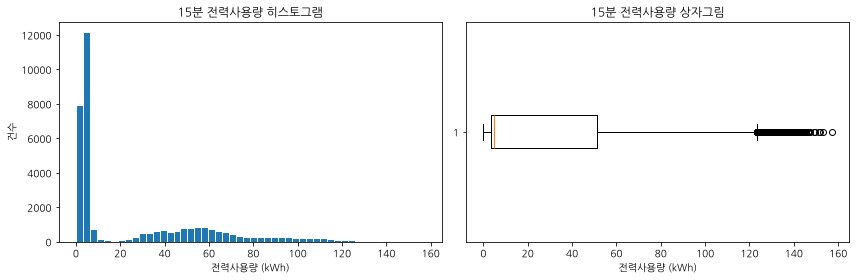

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(usage, bins=50, edgecolor="white")
axes[0].set(title="15분 전력사용량 히스토그램", xlabel="전력사용량 (kWh)", ylabel="건수")
axes[1].boxplot(usage, vert=False)
axes[1].set(title="15분 전력사용량 상자그림", xlabel="전력사용량 (kWh)")
plt.tight_layout()
plt.show()

### 5. `일자` 별로 묶어 하루 단위 표 `daily` 를 만드시오. 전력사용량 · 지상무효전력은 하루 합계, 지상역률은 하루 평균, 주중주말 · 요일은 그날의 값(첫 번째 값)으로 한다. 날짜 수와 하루 기록 수(15분 × 96)를 확인하시오.

In [ ]:
daily = data.groupby("일자").agg(전력사용량=("전력사용량", "sum"),
                                지상무효전력=("지상무효전력", "sum"),
                                지상역률=("지상역률", "mean"),          # 역률은 더하는 값이 아니라 평균으로 묶는다
                                주중주말=("주중주말", "first"),
                                요일=("요일", "first")).reset_index()
print("날짜 수:", len(daily))
print(data.groupby("일자").size().value_counts())    # 하루 기록 수별 날짜 수
daily.head()

날짜 수: 365
96    365
Name: count, dtype: int64


,일자,전력사용량,지상무효전력,지상역률,주중주말,요일
0,2018-01-01,351.86,166.62,85.299375,Weekday,Monday
1,2018-01-02,3950.43,1579.63,84.207292,Weekday,Tuesday
2,2018-01-03,3561.05,1285.59,86.100000,Weekday,Wednesday
3,2018-01-04,4977.72,2059.11,84.128125,Weekday,Thursday
4,2018-01-05,4683.40,1960.60,84.063021,Weekday,Friday


### 6. 주중 · 주말별 하루 전력사용량의 일수 · 평균 · 중앙값 · 표준편차 · 최솟값 · 최댓값을 한 표로 구하고(소수 첫째 자리까지), 상자그림을 나란히 그리시오.

,count,mean,median,std,min,max
주중주말,,,,,,
Weekday,261,3228.0,3119.2,1184.5,259.5,7353.8
Weekend,104,1126.3,769.0,1005.9,264.2,5013.6


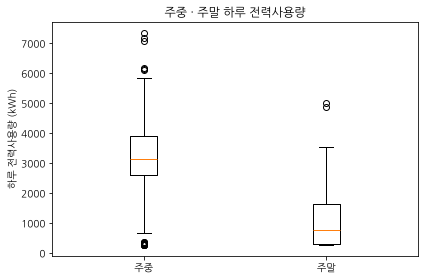

하루 사용량이 1,000kWh 미만인 날 → 주중: 13 일 / 주말: 57 일


In [ ]:
display(daily.groupby("주중주말")["전력사용량"].agg(["count", "mean", "median", "std", "min", "max"]).round(1))

weekday_use = daily.loc[daily["주중주말"] == "Weekday", "전력사용량"]
weekend_use = daily.loc[daily["주중주말"] == "Weekend", "전력사용량"]
plt.figure(figsize=(6, 4))
plt.boxplot([weekday_use, weekend_use], tick_labels=["주중", "주말"])
plt.ylabel("하루 전력사용량 (kWh)")
plt.title("주중 · 주말 하루 전력사용량")
plt.tight_layout()
plt.show()

print("하루 사용량이 1,000kWh 미만인 날 → 주중:", (weekday_use < 1000).sum(), "일 / 주말:", (weekend_use < 1000).sum(), "일")

### 7. 요일별 하루 전력사용량의 평균과 중앙값을 월요일 ~ 일요일 순서로 구하고(소수 첫째 자리까지), 평균을 막대그래프로 그리시오.

,mean,median
요일,,
Monday,3181.8,3147.2
Tuesday,3305.1,3367.7
Wednesday,3096.4,3111.6
Thursday,3370.8,3053.7
Friday,3186.7,2865.8
Saturday,1528.2,1451.0
Sunday,724.4,339.6


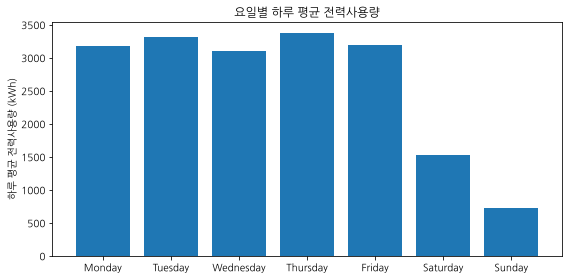

In [ ]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_table = daily.groupby("요일")["전력사용량"].agg(["mean", "median"]).reindex(day_order).round(1)
display(day_table)

plt.figure(figsize=(8, 4))
plt.bar(day_table.index, day_table["mean"])
plt.ylabel("하루 평균 전력사용량 (kWh)")
plt.title("요일별 하루 평균 전력사용량")
plt.tight_layout()
plt.show()

## 2부. 두 집단 비교

### 8. 주중과 주말의 하루 전력사용량을 비교하려 한다. 두 집단 각각 Shapiro-Wilk 정규성 검정 p값과 Levene 검정 p값을 구한 뒤, 알맞은 검정을 골라 검정하고, 통계적 결론과 사실적 결론을 쓰시오.

- 귀무가설(H₀): 주중과 주말의 하루 전력사용량 분포는 같다. (F_주중 = F_주말)
- 대립가설(H₁): 주중과 주말의 하루 전력사용량 분포는 다르다. (F_주중 ≠ F_주말)

In [ ]:
print("주중 shapiro p값:", stats.shapiro(weekday_use).pvalue)
print("주말 shapiro p값:", stats.shapiro(weekend_use).pvalue)
print("levene p값:", round(stats.levene(weekday_use, weekend_use).pvalue, 3))

# 두 집단 모두 정규성이 크게 어긋나고(주중에도 사용량이 아주 적은 날이 몰려 있다) → Mann-Whitney U 검정
mw_result = stats.mannwhitneyu(weekday_use, weekend_use)
print("U:", mw_result.statistic, "/ p값:", mw_result.pvalue)
print("중앙값 → 주중:", round(weekday_use.median(), 1), "/ 주말:", round(weekend_use.median(), 1))

# [답]
# - 통계적 결론 : p < 0.001 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 주중과 주말의 하루 전력사용량 분포는 다르다고 볼 통계적 근거가 있다.
#   주중의 하루 사용량이 주말보다 크게 나타나는 경향이 있다 (중앙값 주중 3,119.2kWh, 주말 769.0kWh)

주중 shapiro p값: 3.0877048501980844e-07
주말 shapiro p값: 3.236631165346572e-10
levene p값: 0.343
U: 24571.0 / p값: 1.2255074873174213e-33
중앙값 → 주중: 3119.2 / 주말: 769.0


## 3부. 여러 집단 비교

### 9. 평일 다섯 요일(월 ~ 금)의 하루 전력사용량이 같은지 비교하려 한다. 요일마다 Shapiro-Wilk p값과 다섯 요일의 Levene p값을 구한 뒤, 알맞은 검정을 골라 검정하고, 통계적 결론과 사실적 결론을 쓰시오. (p값은 소수 셋째 자리까지)

- 귀무가설(H₀): 평일 다섯 요일의 하루 전력사용량 분포는 같다. (F_월 = F_화 = F_수 = F_목 = F_금)
- 대립가설(H₁): 적어도 한 요일의 하루 전력사용량 분포가 다르다. (적어도 한 Fᵢ가 다르다)

In [ ]:
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
groups = [daily.loc[daily["요일"] == day, "전력사용량"] for day in weekdays]    # 요일마다 하루 사용량을 꺼낸다

for day, values in zip(weekdays, groups):
    print(day, "shapiro p값:", round(stats.shapiro(values).pvalue, 3))
print("levene p값:", round(stats.levene(*groups).pvalue, 3))     # *groups : 목록 안의 다섯 집단을 하나씩 풀어 넣는다

# 다섯 요일 중 네 요일의 정규성이 어긋난다 → Kruskal-Wallis 검정
kw_result = stats.kruskal(*groups)
print("H:", round(kw_result.statistic, 3), "/ p값:", round(kw_result.pvalue, 3))

# [답]
# - 통계적 결론 : p = 0.653 ≥ 0.05 이므로 귀무가설을 기각하지 못한다
# - 사실적 결론 : 평일 다섯 요일의 하루 전력사용량 분포가 다르다고 볼 통계적 근거가 부족하다.
#   요일별 평균은 3,096.4 ~ 3,370.8kWh 로 비슷하다

Monday shapiro p값: 0.008
Tuesday shapiro p값: 0.038
Wednesday shapiro p값: 0.316
Thursday shapiro p값: 0.001
Friday shapiro p값: 0.002
levene p값: 0.849
H: 2.455 / p값: 0.653


## 4부. 범주형 자료의 검정

### 10. 15분 기록에서 `주중주말` 과 `부하유형` 의 교차표와 행 비율표(주중 · 주말별 100%)를 구하고, 기대빈도를 확인한 뒤 독립성 검정을 하고, 통계적 결론과 사실적 결론을 쓰시오.

- 귀무가설(H₀): 주중주말과 부하유형은 독립이다. 주중과 주말의 부하유형 비율은 같다. (P(주중주말 ∩ 부하유형) = P(주중주말) × P(부하유형))
- 대립가설(H₁): 주중주말과 부하유형은 독립이 아니다. 주중과 주말의 부하유형 비율이 다르다. (P(주중주말 ∩ 부하유형) ≠ P(주중주말) × P(부하유형))

In [ ]:
load_cross = pd.crosstab(data["주중주말"], data["부하유형"])
display(load_cross)
display((pd.crosstab(data["주중주말"], data["부하유형"], normalize="index") * 100).round(1))

chi_result = stats.chi2_contingency(load_cross)          # 검정에는 비율표가 아니라 건수표를 넣는다
print("가장 작은 기대빈도:", round(chi_result.expected_freq.min(), 1))
print("χ²:", round(chi_result.statistic, 1), "/ p값:", chi_result.pvalue)

# [답]
# - 통계적 결론 : p < 0.001 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 주중주말과 부하유형은 독립이라고 보기 어렵다. 경부하 비율이 주중 44.6%, 주말 69.2% 로 주말에 경부하가 훨씬 많다.
#   다만 15분 연속 기록이라 관측이 독립이라는 가정에는 한계가 있다

부하유형,Light_Load,Maximum_Load,Medium_Load
주중주말,,,
Weekday,11168,5952,7936
Weekend,6904,1320,1760


부하유형,Light_Load,Maximum_Load,Medium_Load
주중주말,,,
Weekday,44.6,23.8,31.7
Weekend,69.2,13.2,17.6


가장 작은 기대빈도: 2072.0
χ²: 1726.8 / p값: 0.0


## 5부. 상관분석

검정 문제는 실습 04의 다섯 단계를 따른다. **목적 · 자료 확인 → 산점도와 방법 우선 선택 → 조건 확인 및 재검토 → 최종 가설 · 검정 → 보고**

### 11. 하루 전력사용량(x)과 하루 지상무효전력(y)의 산점도를 그리고, 피어슨 · 스피어만 상관계수를 구하시오. (소수 셋째 자리까지)

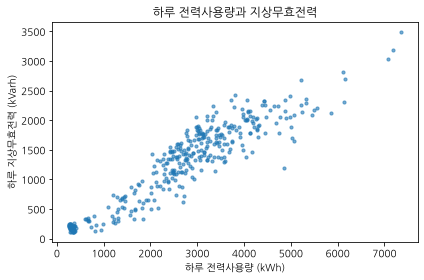

피어슨 r: 0.937
스피어만 ρs: 0.919


In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(daily["전력사용량"], daily["지상무효전력"], s=10, alpha=0.6)
plt.xlabel("하루 전력사용량 (kWh)")
plt.ylabel("하루 지상무효전력 (kVarh)")
plt.title("하루 전력사용량과 지상무효전력")
plt.tight_layout()
plt.show()

print("피어슨 r:", round(daily["전력사용량"].corr(daily["지상무효전력"]), 3))
print("스피어만 ρs:", round(daily["전력사용량"].corr(daily["지상무효전력"], method="spearman"), 3))

### 12. 하루 전력사용량과 하루 평균 지상역률의 피어슨 상관계수를 전체 365일로 구하고, 주중 · 주말로 나눠 다시 구하시오. (소수 셋째 자리까지)

In [ ]:
print("전체 r:", round(daily["전력사용량"].corr(daily["지상역률"]), 3))
daily.groupby("주중주말")[["전력사용량", "지상역률"]].corr().round(3)

전체 r: 0.024


전력사용량   지상역률
주중주말                       
Weekday 전력사용량  1.000  0.224
        지상역률   0.224  1.000
Weekend 전력사용량  1.000  0.079
        지상역률   0.079  1.000

### 13. 주중 261일에서 "하루 전력사용량이 많은 날일수록 지상역률도 높은가"를 검정하려 한다. 산점도를 그리고, 두 변수의 Shapiro-Wilk p값을 확인한 뒤 알맞은 방법으로 상관계수와 p값을 구하시오. 참고값으로 다른 계수도 함께 출력하고, 통계적 결론과 사실적 결론을 쓰시오.

- 귀무가설(H₀): 모집단에서 주중의 하루 전력사용량과 지상역률은 상관이 없다. (ρs = 0)
- 대립가설(H₁): 모집단에서 주중의 하루 전력사용량과 지상역률은 상관이 있다. (ρs ≠ 0)

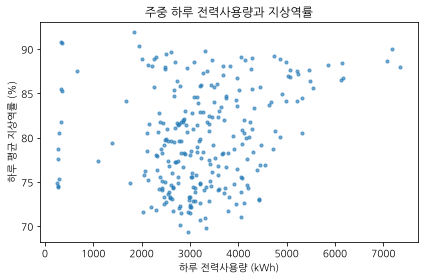

전력사용량 shapiro p값: 3.0877048501980844e-07
지상역률 shapiro p값: 1.5722871572870638e-06
n: 261
ρs: 0.196 / p값: 0.0014
참고 피어슨 r: 0.224


In [ ]:
weekday_daily = daily[daily["주중주말"] == "Weekday"]
x = weekday_daily["전력사용량"]
y = weekday_daily["지상역률"]

plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=10, alpha=0.6)
plt.xlabel("하루 전력사용량 (kWh)")
plt.ylabel("하루 평균 지상역률 (%)")
plt.title("주중 하루 전력사용량과 지상역률")
plt.tight_layout()
plt.show()

print("전력사용량 shapiro p값:", stats.shapiro(x).pvalue)
print("지상역률 shapiro p값:", stats.shapiro(y).pvalue)

# 휜 곡선은 아니지만 사용량이 아주 적은 날이 왼쪽에 떨어져 있고, 두 변수 모두 정규성이 크게 어긋난다
# 목적이 '많은 날일수록 높은가'(순위상 증가 관계)라 스피어만으로 정한다
pf_result = stats.spearmanr(x, y)
print("n:", len(weekday_daily))
print("ρs:", round(pf_result.statistic, 3), "/ p값:", round(pf_result.pvalue, 4))
print("참고 피어슨 r:", round(x.corr(y), 3))

# [답]
# - 통계적 결론 : p = 0.0014 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 모집단에서 주중의 하루 전력사용량과 지상역률은 상관이 있다고 볼 통계적 근거가 있다.
#   다만 ρs = 0.196 으로 약한 양의 상관이다. p값은 '0 이 아니다'까지만 알려 주고, 강도는 계수로 읽는다